### RQ1a description: How is each occupation's frozen task universe distributed across Automation-oriented, Augmentation-oriented, and Limited GenAI applicability mechanisms, and where do those mechanisms sit in the within-occupation importance ordering?

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

BASE_DIR = Path(
    "/content/drive/MyDrive/GenAI-task-affordance-labor-outcomes-full"
)

configuration_data = pd.read_csv(
    BASE_DIR
    / "05_Layer3_Task_Configuration/Output/Occupational_Task_Affordance_Configuration_v6.csv",
    dtype={"soc6": "string"},
)

exposure_data = pd.read_csv(
    BASE_DIR
    / "07_GenAI_Exposure/Output/Occupational_Configuration_Exposure_v1.csv",
    dtype={"soc6": "string"},
)

outcome_data = pd.read_csv(
    BASE_DIR / "08_Labor_Outcomes/Output/OEWS_Occupational_Outcomes_v1.csv",
    dtype={"soc6": "string"},
)
mechanisms = ["automation", "augmentation", "limited"]

### RQ1a: Mechanism composition

In [ ]:
composition_rows = []

for mechanism in mechanisms:
    share = configuration_data[f"{mechanism}_share"]
    occupations = share.count()
    absent_n = share.eq(0).sum()

    composition_rows.append({
        "mechanism": mechanism.title(),
        "occupations": occupations,
        "present_n": share.gt(0).sum(),
        "absent_n": absent_n,
        "absent_pct": 100 * absent_n / occupations,
        "mean_share": share.mean(),
        "std_share": share.std(),
        "median_share": share.median(),
        "p25_share": share.quantile(0.25),
        "p75_share": share.quantile(0.75),
        "min_share": share.min(),
        "max_share": share.max(),
    })

rq1a_composition_summary = pd.DataFrame(composition_rows)

### RQ1a: Importance positions

In [ ]:
position_rows = []
rq1a_positions = {}

for mechanism in mechanisms:
    present = configuration_data[f"{mechanism}_count"].gt(0)
    position = configuration_data.loc[
        present, f"{mechanism}_position"
    ].dropna()

    rq1a_positions[mechanism] = position

    position_rows.append({
        "mechanism": mechanism.title(),
        "position_observed_n": len(position),
        "position_unavailable_n": present.sum() - len(position),
        "mean_position": position.mean(),
        "std_position": position.std(),
        "median_position": position.median(),
        "p25_position": position.quantile(0.25),
        "p75_position": position.quantile(0.75),
        "min_position": position.min(),
        "max_position": position.max(),
    })

rq1a_position_summary = pd.DataFrame(position_rows)

In [ ]:
table1_columns = ["N", "Mean", "SD", "Min", "Max"]

table1_parts = {
    "Aggregate GenAI exposure": (
        exposure_data[["human_beta"]]
        .agg(["count", "mean", "std", "min", "max"]).T
        .rename(index={"human_beta": "Human Beta"})
    ),
    "Task share": (
        rq1a_composition_summary.set_index("mechanism")[
            ["occupations", "mean_share", "std_share", "min_share", "max_share"]
        ]
    ),
    "Importance position": (
        rq1a_position_summary.set_index("mechanism")[
            ["position_observed_n", "mean_position", "std_position",
             "min_position", "max_position"]
        ]
    ),
    "Change": (
        outcome_data[
            ["employment_ann_log_change", "mean_wage_ann_log_change"]
        ].mul(100)
        .agg(["count", "mean", "std", "min", "max"]).T
        .rename(index={
            "employment_ann_log_change": "Employment",
            "mean_wage_ann_log_change": "Wage",
        })
    ),
}

table1_rows = []
for section, values in table1_parts.items():
    table1_rows.append([section, *[np.nan] * 5])
    values = values.rename(index={"Limited": "Limited applicability"})
    table1_rows.extend([label, *row] for label, row in values.iterrows())

table1 = pd.DataFrame(
    table1_rows, columns=["Variable", *table1_columns]
)

display(
    table1.style.hide(axis="index")
    .format(
        {"N": "{:.0f}", **{c: "{:.3f}" for c in table1_columns[1:]}},
        na_rep=""
    )
    .apply(
        lambda row: [
            "font-weight: bold" if row["Variable"] in table1_parts else ""
        ] * len(row),
        axis=1
    )
    .set_caption("Table 1. Descriptive statistics of occupational measures.")
)

Variable,N,Mean,SD,Min,Max
Aggregate GenAI exposure,,,,,
Human Beta,771,0.286,0.207,0.000,0.844
Task share,,,,,
Automation,771,0.045,0.067,0.000,0.467
Augmentation,771,0.423,0.245,0.000,1.000
Limited applicability,771,0.533,0.268,0.000,1.000
Importance position,,,,,
Automation,340,0.472,0.232,0.017,0.983
Augmentation,722,0.525,0.125,0.107,0.981
Limited applicability,743,0.485,0.097,0.033,0.870


### RQ1a: Main figure

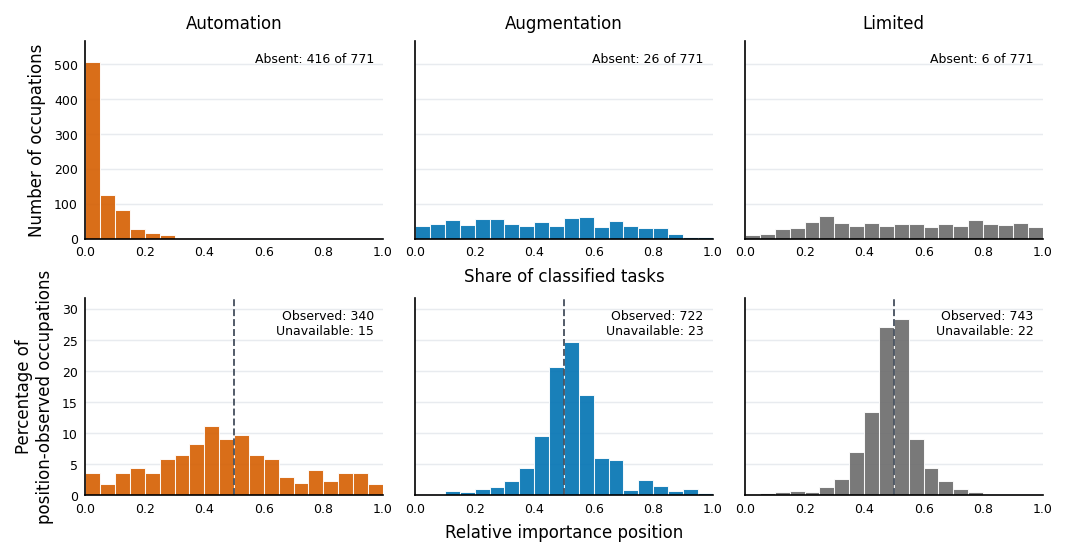

In [ ]:
colors = ["#D55E00", "#0072B2", "#6B6B6B"]
bins = np.linspace(0, 1, 21)

fig_combined, axes_combined = plt.subplots(
    2, 3, figsize=(7, 3.6), dpi=150,
    sharex="row", sharey="row", layout="constrained",
    facecolor="white",
)

for column, (mechanism, color) in enumerate(zip(mechanisms, colors)):
    ax_share, ax_position = axes_combined[:, column]
    share = configuration_data[f"{mechanism}_share"]
    position = rq1a_positions[mechanism]

    ax_share.hist(
        share, bins=bins, color=color,
        edgecolor="white", linewidth=0.5, alpha=0.9,
    )
    ax_share.set_title(mechanism.title(), fontsize=8)
    ax_share.text(
        0.97, 0.94,
        f"Absent: {rq1a_composition_summary.loc[column, 'absent_n']}"
        f" of {len(configuration_data)}",
        transform=ax_share.transAxes, ha="right", va="top", fontsize=6,
    )

    ax_position.hist(
        position, bins=bins, color=color,
        weights=np.full(len(position), 100 / len(position)),
        edgecolor="white", linewidth=0.5, alpha=0.9,
    )
    ax_position.axvline(0.5, color="#4B5563", linestyle="--", linewidth=0.9)
    ax_position.text(
        0.97, 0.94,
        f"Observed: {len(position)}\n"
        f"Unavailable: {rq1a_position_summary.loc[column, 'position_unavailable_n']}",
        transform=ax_position.transAxes, ha="right", va="top", fontsize=6,
    )

for ax in axes_combined.flat:
    ax.set_facecolor("white")
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#E8EBEF", linewidth=0.7)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="both", length=0, labelsize=6)
    ax.set_xlim(0, 1)
    ax.set_xticks(np.linspace(0, 1, 6))
    ax.margins(y=0.12)

axes_combined[0, 1].set_xlabel("Share of classified tasks", fontsize=8)
axes_combined[1, 1].set_xlabel("Relative importance position", fontsize=8)
axes_combined[0, 0].set_ylabel("Number of occupations", fontsize=8)
axes_combined[1, 0].set_ylabel(
    "Percentage of\nposition-observed occupations", fontsize=8
)

fig_combined.savefig(
    BASE_DIR / "09_RQ1_Analysis/Figures/task_share_imp_positions.png",
    dpi=300, bbox_inches="tight", facecolor="white",
)
plt.show()

### Audit For RQ1 a

In [ ]:
audit_a1 = pd.DataFrame([
    {
        "Mechanism": row.mechanism,
        "Present (n) (%)":
            f"{row.present_n} ({100 * row.present_n / row.occupations:.1f})",
        "Mean task share (%)": f"{100 * row.mean_share:.1f}",
        "Position observed (n)": row.position_observed_n,
        "Mean importance position (SD)":
            f"{row.mean_position:.3f} ({row.std_position:.3f})",
    }
    for row in rq1a_composition_summary.merge(
        rq1a_position_summary, on="mechanism"
    ).itertuples(index=False)
])

print("A1 Table. Task shares and importance positions.")
display(audit_a1.style.hide(axis="index"))

print(
    f"Note. Task-share statistics include all {len(configuration_data)} occupations, "
    "with absent categories assigned a share of zero. Importance-position statistics "
    "include only occupations where the category was present and its position was available."
)

A1 Table. Task shares and importance positions.


Mechanism,Present (n) (%),Mean task share (%),Position observed (n),Mean importance position (SD)
Automation,355 (46.0),4.5,340,0.472 (0.232)
Augmentation,745 (96.6),42.3,722,0.525 (0.125)
Limited,765 (99.2),53.3,743,0.485 (0.097)


Note. Task-share statistics include all 771 occupations, with absent categories assigned a share of zero. Importance-position statistics include only occupations where the category was present and its position was available.


### RQ1b: Prepare model data

In [ ]:
model_data = (
    configuration_data.drop(columns="human_beta", errors="ignore")
    .merge(exposure_data[["soc6", "human_beta"]], on="soc6", how="left")
    .merge(outcome_data, on="soc6", how="left")
)

eligible = model_data[
    ["human_beta", *[f"{m}_share" for m in mechanisms]]
].notna().all(axis=1)

for mechanism in mechanisms:
    present = model_data[f"{mechanism}_count"].gt(0)
    position = model_data[f"{mechanism}_position"]

    eligible &= ~(present & position.isna())
    model_data[f"{mechanism}_position_centered"] = (
        position - 0.5
    ).where(present, 0.0)

model_data["automation_present"] = model_data["automation_count"].gt(0).astype(int)
model_data["augmentation_absent"] = model_data["augmentation_count"].eq(0).astype(int)
model_data["limited_absent"] = model_data["limited_count"].eq(0).astype(int)

outcomes = {
    "Employment": "employment_ann_log_change",
    "Wage": "mean_wage_ann_log_change",
    "Median wage": "median_wage_ann_log_change",
}

samples = {
    outcome: model_data.loc[eligible & model_data[column].notna()].copy()
    for outcome, column in outcomes.items()
}

### RQ1b: Fit M0–M2

In [ ]:
composition_terms = ["automation_share", "augmentation_share"]
state_terms = [
    "automation_present", "augmentation_absent", "limited_absent"
]
position_terms = [f"{m}_position_centered" for m in mechanisms]

model_terms = {"M0": ["human_beta"]}
model_terms["M1"] = model_terms["M0"] + composition_terms
model_terms["M2"] = model_terms["M1"] + state_terms + position_terms

models = {}

for outcome, frame in samples.items():
    y = frame[outcomes[outcome]]

    models[outcome] = {
        name: sm.OLS(
            y,
            sm.add_constant(frame[terms], has_constant="add"),
        ).fit(cov_type="HC3")
        for name, terms in model_terms.items()
    }

### RQ1b: Joint tests

In [ ]:
wald_specs = [
    ("Layer 1 — Mechanism composition", "M1 vs. M0",
     "M1", composition_terms),
    ("Layer 3 — Structural states and importance positions", "M2 vs. M1",
     "M2", state_terms + position_terms),
    ("Full task-affordance configuration", "M2 vs. M0",
     "M2", model_terms["M2"][1:]),
    ("Layer 3 — Importance positions", "Within M2",
     "M2", position_terms),
]

wald_rows = []

for outcome, fitted in models.items():
    for block, comparison, model, terms in wald_specs:
        test = fitted[model].wald_test(
            ", ".join(f"{term} = 0" for term in terms),
            use_f=True,
            scalar=True,
        )

        wald_rows.append({
            "Outcome": outcome,
            "Block": block,
            "Comparison": comparison,
            "F": float(test.statistic),
            "df_num": int(test.df_num),
            "df_denom": int(test.df_denom),
            "p": float(test.pvalue),
        })

wald_results = pd.DataFrame(wald_rows)

### RQ1b: Main results tables

In [ ]:
def format_p_value(p):
    return "< .001" if p < .001 else f"= {p:.3f}".replace("0.", ".")

table_2 = pd.DataFrame({
    "Block tested": [
        "mechanism composition",
        "structural states and importance positions",
        "task-affordance configuration",
        "importance positions",
    ],
    "Comparison": [
        "M1 vs. M0",
        "M2 vs. M1",
        "M2 vs. M0",
        "within M2: joint test",
    ],
})

for outcome in ["Employment", "Wage"]:
    results = wald_results.loc[wald_results["Outcome"].eq(outcome)]
    n = int(models[outcome]["M2"].nobs)

    table_2[f"{outcome} (N = {n})"] = [
        f"F ({row.df_num}, {row.df_denom}) = {row.F:.3f}, "
        f"p {format_p_value(row.p)}"
        for row in results.itertuples(index=False)
    ]

print("Table 2. Joint tests by block.")
display(table_2.style.hide(axis="index"))
print("Note. Entries are HC3-robust Wald F tests.")

Table 2. Joint tests by block.


Block tested,Comparison,Employment (N = 699),Wage (N = 697)
mechanism composition,M1 vs. M0,"F (2, 695) = 21.107, p < .001","F (2, 693) = 4.954, p = .007"
structural states and importance positions,M2 vs. M1,"F (6, 689) = 4.446, p < .001","F (6, 687) = 1.754, p = .106"
task-affordance configuration,M2 vs. M0,"F (8, 689) = 9.418, p < .001","F (8, 687) = 2.425, p = .014"
importance positions,within M2: joint test,"F (3, 689) = 6.010, p < .001","F (3, 687) = 1.252, p = .290"


Note. Entries are HC3-robust Wald F tests.


### RQ1b.3: Specific augmentation comparison

In [ ]:
coefficient_rows = []

for outcome in ["Employment", "Wage"]:
    for name, fitted in models[outcome].items():
        ci = fitted.conf_int() * 100

        for term in model_terms[name]:
            coefficient_rows.append({
                "Outcome": outcome,
                "Model": name,
                "N": int(fitted.nobs),
                "Term": term,
                "Estimate [95% CI]": (
                    f"{100 * fitted.params[term]:.4f} "
                    f"[{ci.loc[term, 0]:.4f}, {ci.loc[term, 1]:.4f}]"
                ),
                "p value": format_p_value(
                    fitted.pvalues[term]
                ).removeprefix("= "),
            })

coefficient_results = pd.DataFrame(coefficient_rows)

### S1 Table. Model fit across specifications

In [ ]:
specifications = {
    "M0": "Aggregate GenAI exposure",
    "M1": "M0 + mechanism composition",
    "M2": "M1 + structural states and importance positions",
}

supplement_s1 = pd.DataFrame([
    {
        "Outcome": outcome,
        "Model": name,
        "Specification": specifications[name],
        "N": int(fitted.nobs),
        "R²": fitted.rsquared,
        "Adjusted R²": fitted.rsquared_adj,
    }
    for outcome, outcome_models in models.items()
    for name, fitted in outcome_models.items()
])

supplement_s1["ΔR²"] = supplement_s1.groupby("Outcome")["R²"].diff()

print("S1 Table. Model fit across specifications.")
display(
    supplement_s1.style.hide(axis="index").format(
        {column: "{:.4f}" for column in ["R²", "Adjusted R²", "ΔR²"]},
        na_rep="—",
    )
)
print(
    "Note. ΔR² is the change from the preceding model. "
    "M0–M2 use the same occupations within each outcome."
)

S1 Table. Model fit across specifications.


Outcome,Model,Specification,N,R²,Adjusted R²,ΔR²
Employment,M0,Aggregate GenAI exposure,699,0.0297,0.0283,—
Employment,M1,M0 + mechanism composition,699,0.0792,0.0752,0.0495
Employment,M2,M1 + structural states and importance positions,699,0.1162,0.1046,0.0370
Wage,M0,Aggregate GenAI exposure,697,0.0798,0.0784,—
Wage,M1,M0 + mechanism composition,697,0.0940,0.0900,0.0142
Wage,M2,M1 + structural states and importance positions,697,0.1064,0.0947,0.0124
Median wage,M0,Aggregate GenAI exposure,683,0.0912,0.0898,—
Median wage,M1,M0 + mechanism composition,683,0.1066,0.1027,0.0155
Median wage,M2,M1 + structural states and importance positions,683,0.1256,0.1139,0.0190


Note. ΔR² is the change from the preceding model. M0–M2 use the same occupations within each outcome.


### S2 Table. Coefficient estimates

In [ ]:
s2_predictors = [
    ("human_beta", "Aggregate GenAI exposure"),
    (None, "Mechanism composition"),
    ("automation_share", "Automation share"),
    ("augmentation_share", "Augmentation share"),
    (None, "Structural states"),
    ("automation_present", "Automation present"),
    ("augmentation_absent", "Augmentation absent"),
    ("limited_absent", "Limited absent"),
    (None, "Importance positions (centered)"),
    ("automation_position_centered", "Automation"),
    ("augmentation_position_centered", "Augmentation"),
    ("limited_position_centered", "Limited"),
]

s2_columns = {
    "M0": "M0: Exposure",
    "M1": "M1: + Composition",
    "M2": "M2: + States and positions",
}

coefficient_results["Entry"] = (
    coefficient_results["Estimate [95% CI]"] + "\np "
    + coefficient_results["p value"].map(
        lambda p: p if p.startswith("<") else f"= {p}"
    )
)

s2_rows = []

for outcome, group in coefficient_results.groupby("Outcome", sort=False):
    estimates = group.pivot(
        index="Term", columns="Model", values="Entry"
    ).reindex(columns=s2_columns).fillna("—")

    s2_rows.append({"Predictor": f"{outcome} (N = {group['N'].iloc[0]})"})

    for term, label in s2_predictors:
        s2_rows.append({
            "Predictor": label,
            **{
                heading: estimates.at[term, model] if term else ""
                for model, heading in s2_columns.items()
            },
        })

supplement_s2 = pd.DataFrame(s2_rows).fillna("")

In [ ]:
print("S2 Table. Coefficient estimates.")
display(
    supplement_s2.style.hide(axis="index")
    .set_properties(**{"white-space": "pre-line", "text-align": "left"})
)
print(
    "Note. Entries report unstandardized coefficients with HC3-based "
    "95% confidence intervals in brackets and p values. Outcomes are "
    "annualized log changes × 100; task shares use a 0–1 scale, with "
    "Limited as the reference category. "
    "— indicates a term not included in the model."
)

S2 Table. Coefficient estimates.


Predictor,M0: Exposure,M1: + Composition,M2: + States and positions
Employment (N = 699),,,
Aggregate GenAI exposure,"3.2708 [1.8020, 4.7396] p < .001","1.2999 [-1.7264, 4.3262] p = .400","1.6786 [-1.3849, 4.7421] p = .283"
Mechanism composition,,,
Automation share,—,"-9.9124 [-15.0377, -4.7871] p < .001","-12.4710 [-19.3052, -5.6369] p < .001"
Augmentation share,—,"3.5960 [1.3773, 5.8147] p = .001","2.8729 [0.6677, 5.0780] p = .011"
Structural states,,,
Automation present,—,—,"0.5104 [-0.4052, 1.4260] p = .275"
Augmentation absent,—,—,"-1.5633 [-2.9565, -0.1702] p = .028"
Limited absent,—,—,"-3.5904 [-8.0905, 0.9097] p = .118"
Importance positions (centered),,,


Note. Entries report unstandardized coefficients with HC3-based 95% confidence intervals in brackets and p values. Outcomes are annualized log changes × 100; task shares use a 0–1 scale, with Limited as the reference category. — indicates a term not included in the model.


### Audit

In [ ]:
audit_a2 = table_2[["Block tested", "Comparison"]].copy()
audit_a2.columns = pd.MultiIndex.from_tuples(
    [(column, "") for column in audit_a2.columns]
)

influential_socs = {}
omission_p = {}

for outcome in ["Employment", "Wage"]:
    frame = samples[outcome]
    selected = set()

    for name in ["M1", "M2"]:
        influence = models[outcome][name].get_influence()

        # Existing rule: top 5 Cook's distances, top 3 leverages,
        # and largest absolute DFBETAS for each configuration term.
        selected.update(
            pd.Series(influence.cooks_distance[0]).nlargest(5).index
        )
        selected.update(
            pd.Series(influence.hat_matrix_diag).nlargest(3).index
        )
        selected.update(
            np.abs(influence.dfbetas[:, 2:]).argmax(axis=0)
        )

    influential_socs[outcome] = sorted(frame.iloc[list(selected)]["soc6"])
    p_rows = []

    for soc6 in influential_socs[outcome]:
        reduced = frame.loc[frame["soc6"].ne(soc6)]

        reduced_models = {
            name: sm.OLS(
                reduced[outcomes[outcome]],
                sm.add_constant(reduced[model_terms[name]], has_constant="add"),
            ).fit(cov_type="HC3")
            for name in ["M1", "M2"]
        }

        p_rows.append([
            float(reduced_models[name].wald_test(
                ", ".join(f"{term} = 0" for term in terms),
                use_f=True,
                scalar=True,
            ).pvalue)
            for _, _, name, terms in wald_specs
        ])

    omission_p[outcome] = pd.DataFrame(
        p_rows,
        index=pd.Index(influential_socs[outcome], name="Excluded SOC6"),
        columns=[block for block, *_ in wald_specs],
    )

    audit_a2[(outcome, "Full-sample p")] = [
        format_p_value(p).removeprefix("= ")
        for p in wald_results.loc[wald_results["Outcome"].eq(outcome), "p"]
    ]
    audit_a2[(outcome, "Exclusion p range")] = [
        "All < .001" if high < .001 else
        f"{format_p_value(low).removeprefix('= ')} – "
        f"{format_p_value(high).removeprefix('= ')}"
        for low, high in zip(
            omission_p[outcome].min(), omission_p[outcome].max()
        )
    ]

print("A2 Table. Joint tests to individual occupations.")
display(audit_a2.style.hide(axis="index"))
print(
    f"Note. Influence diagnostics selected "
    f"{len(influential_socs['Employment'])} occupations for employment and "
    f"{len(influential_socs['Wage'])} for wage. Each was excluded separately "
    f"from its outcome’s full sample. Full-sample sizes were "
    f"{len(samples['Employment'])} and {len(samples['Wage'])}, respectively, "
    "and decreased by one in each check. Entries report HC3-robust Wald "
    "test p values using the specifications in Table 2."
)

A2 Table. Joint tests to individual occupations.


Note. Influence diagnostics selected 17 occupations for employment and 13 for wage. Each was excluded separately from its outcome’s full sample. Full-sample sizes were 699 and 697, respectively, and decreased by one in each check. Entries report HC3-robust Wald test p values using the specifications in Table 2.


In [ ]:
gpt4_beta = exposure_data.set_index("soc6")["gpt4_beta"]
benchmark_models = {}
a3_parts = []

for outcome in ["Employment", "Wage"]:
    frame = samples[outcome].assign(
        gpt4_beta=samples[outcome]["soc6"].map(gpt4_beta)
    )

    benchmark_models[outcome] = {
        name: sm.OLS(
            frame[outcomes[outcome]],
            sm.add_constant(
                frame[[
                    "gpt4_beta" if term == "human_beta" else term
                    for term in terms
                ]],
                has_constant="add",
            ),
            missing="raise",
        ).fit(cov_type="HC3")
        for name, terms in model_terms.items()
    }

    part = table_2[["Block tested", "Comparison"]].copy()
    part["Human Beta"] = table_2[f"{outcome} (N = {len(frame)})"]
    benchmark_entries = []

    for _, _, name, terms in wald_specs:
        test = benchmark_models[outcome][name].wald_test(
            ", ".join(f"{term} = 0" for term in terms),
            use_f=True,
            scalar=True,
        )
        benchmark_entries.append(
            f"F ({int(test.df_num)}, {int(test.df_denom)}) = "
            f"{float(test.statistic):.3f}, "
            f"p {format_p_value(float(test.pvalue))}"
        )

    part["GPT-4 Beta"] = benchmark_entries
    a3_parts.extend([
        pd.DataFrame([{"Block tested": outcome}]),
        part,
    ])

audit_a3 = pd.concat(a3_parts, ignore_index=True).fillna("")

print("A3 Table. Joint tests to exposure benchmark.")
display(audit_a3.style.hide(axis="index"))
print(
    f"Note. Benchmark comparisons use the same occupations within each outcome: "
    f"{len(samples['Employment'])} for employment and "
    f"{len(samples['Wage'])} for wage. GPT-4 Beta replaces Human Beta in M0–M2, "
    "with configuration terms unchanged. Entries report HC3-robust Wald F tests; "
    "model specifications otherwise follow Table 2."
)

A3 Table. Joint tests to exposure benchmark.


Block tested,Comparison,Human Beta,GPT-4 Beta
Employment,,,
mechanism composition,M1 vs. M0,"F (2, 695) = 21.107, p < .001","F (2, 695) = 31.434, p < .001"
structural states and importance positions,M2 vs. M1,"F (6, 689) = 4.446, p < .001","F (6, 689) = 4.030, p < .001"
task-affordance configuration,M2 vs. M0,"F (8, 689) = 9.418, p < .001","F (8, 689) = 11.538, p < .001"
importance positions,within M2: joint test,"F (3, 689) = 6.010, p < .001","F (3, 689) = 5.511, p < .001"
Wage,,,
mechanism composition,M1 vs. M0,"F (2, 693) = 4.954, p = .007","F (2, 693) = 7.542, p < .001"
structural states and importance positions,M2 vs. M1,"F (6, 687) = 1.754, p = .106","F (6, 687) = 2.070, p = .055"
task-affordance configuration,M2 vs. M0,"F (8, 687) = 2.425, p = .014","F (8, 687) = 3.430, p < .001"
importance positions,within M2: joint test,"F (3, 687) = 1.252, p = .290","F (3, 687) = 1.228, p = .299"


Note. Benchmark comparisons use the same occupations within each outcome: 699 for employment and 697 for wage. GPT-4 Beta replaces Human Beta in M0–M2, with configuration terms unchanged. Entries report HC3-robust Wald F tests; model specifications otherwise follow Table 2.


In [ ]:
structural_eligible = model_data["soc6"].map(
    pd.read_csv(
        BASE_DIR / "08_Labor_Outcomes/Output/OEWS_Annual_Harmonized_Panel_v1.csv",
        usecols=["soc6", "emp_mean_structural_ok"],
        dtype={"soc6": "string"},
    )
    .groupby("soc6")["emp_mean_structural_ok"].all()
)

starting_n = len(model_data)
structural_n = int(structural_eligible.sum())

audit_a4 = pd.DataFrame({
    "Stage": [
        "starting occupation set",
        "excluded by historical correspondence rules",
        "structurally eligible occupations",
        "excluded for incomplete outcome data",
        "complete outcomes before regression restrictions",
        "additional regression exclusion",
        "final regression sample",
    ]
})

for outcome in ["Employment", "Wage"]:
    complete_n = int(
        model_data.loc[structural_eligible, outcomes[outcome]].notna().sum()
    )
    final_n = len(samples[outcome])

    audit_a4[outcome] = [
        starting_n,
        starting_n - structural_n,
        structural_n,
        structural_n - complete_n,
        complete_n,
        complete_n - final_n,
        final_n,
    ]

print("A4 Table. SOC harmonization and sample construction.")
display(audit_a4.style.hide(axis="index"))
print(
    "Note. Historical correspondence rules exclude split or complex SOC "
    "mappings and retain valid complete predecessor mergers. Complete "
    "outcomes require observations in all six analysis years. Additional "
    "regression exclusions reflect missing exposure or required configuration "
    "measures. Each outcome uses a common sample across M0–M2."
)

A4 Table. SOC harmonization and sample construction.


Stage,Employment,Wage
starting occupation set,771,771
excluded by historical correspondence rules,70,70
structurally eligible occupations,701,701
excluded for incomplete outcome data,1,3
complete outcomes before regression restrictions,700,698
additional regression exclusion,1,1
final regression sample,699,697


Note. Historical correspondence rules exclude split or complex SOC mappings and retain valid complete predecessor mergers. Complete outcomes require observations in all six analysis years. Additional regression exclusions reflect missing exposure or required configuration measures. Each outcome uses a common sample across M0–M2.


### RQ1c: Occupational-group heterogeneity

### Fit the six-group models

In [ ]:
group_labels = [
    "Management, business and financial",
    "Professional and related",
    "Service",
    "Sales and office",
    "Natural resources, construction and maintenance",
    "Production, transportation and material moving",
]

occupational_models = {}

for outcome, frame in samples.items():
    frame["occupation_group"] = pd.cut(
        frame["soc6"].str[:2].astype(int),
        bins=[10, 13, 29, 39, 43, 49, 53],
        labels=group_labels,
    )

    columns = {}

    for group, part in frame.groupby("occupation_group", observed=True):
        member = frame["occupation_group"].eq(group).astype(float)
        columns[f"{group}:Intercept"] = member

        for term in model_terms["M2"]:
            if part[term].nunique() > 1:
                columns[f"{group}:{term}"] = frame[term] * member

    X = pd.DataFrame(columns, index=frame.index)
    fitted = sm.OLS(frame[outcomes[outcome]], X, hasconst=True).fit()

    # Prevent inference from unidentified or perfectly fitted terms.
    if fitted.model.rank < X.shape[1] or (
        fitted.get_influence().hat_matrix_diag >= 1 - 1e-10
    ).any():
        raise ValueError(
            f"{outcome}: some group-specific terms are unidentified "
            "or perfectly fit individual occupations; revise those terms "
            "before calculating heterogeneity tests."
        )

    occupational_models[outcome] = fitted.get_robustcov_results(
        cov_type="HC3", use_t=False
    )

### Joint heterogeneity tests

In [ ]:
occupational_wald_rows = []

for outcome, fitted in occupational_models.items():
    names = fitted.model.exog_names
    identity = np.eye(len(names))

    for block, (_, _, _, terms) in zip(
        table_2["Block tested"], wald_specs
    ):
        restrictions = []

        for term in terms:
            indices = [
                i for i, name in enumerate(names)
                if name.endswith(f":{term}")
            ]
            restrictions.extend(
                identity[i] - identity[indices[0]]
                for i in indices[1:]
            )

        test = fitted.wald_test(
            np.asarray(restrictions),
            use_f=True,
            scalar=True,
        )

        occupational_wald_rows.append({
            "Outcome": outcome,
            "Block tested": block,
            "N": int(fitted.nobs),
            "F": float(test.statistic),
            "df_num": int(test.df_num),
            "df_denom": int(test.df_denom),
            "p": float(test.pvalue),
        })

occupational_wald_results = pd.DataFrame(occupational_wald_rows)

### Main results table

In [ ]:
table_3 = table_2[["Block tested"]].copy()

for outcome in ["Employment", "Wage"]:
    results = occupational_wald_results.loc[
        occupational_wald_results["Outcome"].eq(outcome)
    ].set_index("Block tested")

    table_3[f"{outcome} (N = {results['N'].iloc[0]})"] = [
        f"F ({r.df_num}, {r.df_denom}) = {r.F:.3f}; p "
        + ("< .001" if r.p < .001 else f"= {r.p:.4f}".replace("0.", "."))
        for r in results.loc[table_3["Block tested"]].itertuples()
    ]

display(
    table_3.style
    .hide(axis="index")
    .set_caption("Table 3. Joint tests of occupational-group heterogeneity.")
    .set_properties(**{"font-size": "12px", "text-align": "left"})
)

print(
    "Note. Entries report HC3-robust Wald F tests of coefficient equality "
    "across the six broader occupational groups in group-specific M2 models. "
    "Each coefficient is compared only across groups in which it is estimable. "
    "These tests assess differences across groups, rather than whether "
    "coefficients within a group are equal to zero."
)

Block tested,Employment (N = 699),Wage (N = 697)
mechanism composition,"F (10, 647) = 1.542; p = .1203","F (10, 645) = 1.489; p = .1391"
structural states and importance positions,"F (22, 647) = 1.054; p = .3944","F (22, 645) = 0.948; p = .5310"
task-affordance configuration,"F (32, 647) = 1.211; p = .1988","F (32, 645) = 1.400; p = .0723"
importance positions,"F (15, 647) = 1.164; p = .2951","F (15, 645) = 0.766; p = .7158"


Note. Entries report HC3-robust Wald F tests of coefficient equality across the six broader occupational groups in group-specific M2 models. Each coefficient is compared only across groups in which it is estimable. These tests assess differences across groups, rather than whether coefficients within a group are equal to zero.


### Four-sector joint tests

In [ ]:
sector_cols = {
    "Education": "sector_education",
    "Finance": "sector_finance",
    "Healthcare": "sector_healthcare",
    "Legal": "sector_legal",
}

sector_samples = {}
sector_models = {}

for outcome, frame in samples.items():
    stack = pd.concat([
        frame.loc[frame[column].eq(1)].assign(sector=sector)
        for sector, column in sector_cols.items()
    ], ignore_index=True)

    columns = {}

    for sector, part in stack.groupby("sector"):
        member = stack["sector"].eq(sector).astype(float)
        columns[f"{sector}:Intercept"] = member

        # Constant predictors are absorbed by the sector intercept.
        for term in model_terms["M2"]:
            if part[term].nunique() > 1:
                columns[f"{sector}:{term}"] = stack[term] * member

    X = pd.DataFrame(columns, index=stack.index)
    fitted = sm.OLS(stack[outcomes[outcome]], X, hasconst=True).fit(
        cov_type="cluster",
        cov_kwds={"groups": stack["soc6"], "use_correction": True},
        use_t=True,
    )

    if fitted.model.rank < X.shape[1]:
        raise ValueError(f"{outcome}: sector coefficients are not fully identified.")

    sector_samples[outcome] = stack
    sector_models[outcome] = fitted

In [ ]:
sector_wald_rows = []

for outcome, fitted in sector_models.items():
    names = fitted.model.exog_names
    identity = np.eye(len(names))
    n = sector_samples[outcome]["soc6"].nunique()

    for block, (_, _, _, terms) in zip(
        table_2["Block tested"], wald_specs
    ):
        restrictions = []

        for term in terms:
            indices = [
                i for i, name in enumerate(names)
                if name.endswith(f":{term}")
            ]
            restrictions.extend(
                identity[i] - identity[indices[0]]
                for i in indices[1:]
            )

        test = fitted.wald_test(
            np.asarray(restrictions), use_f=True, scalar=True
        )

        sector_wald_rows.append({
            "Outcome": outcome,
            "Block tested": block,
            "N": n,
            "F": float(test.statistic),
            "df_num": int(test.df_num),
            "df_denom": int(test.df_denom),
            "p": float(test.pvalue),
        })

sector_wald_results = pd.DataFrame(sector_wald_rows)

In [ ]:
table_3_sector = table_2[["Block tested"]].copy()

for outcome in ["Employment", "Wage"]:
    results = sector_wald_results.loc[
        sector_wald_results["Outcome"].eq(outcome)
    ].set_index("Block tested")

    table_3_sector[f"{outcome} (N = {results['N'].iloc[0]})"] = [
        f"F ({r.df_num}, {r.df_denom}) = {r.F:.3f}; p "
        + ("< .001" if r.p < .001 else f"= {r.p:.4f}".replace("0.", "."))
        for r in results.loc[table_3_sector["Block tested"]].itertuples()
    ]

display(
    table_3_sector.style
    .hide(axis="index")
    .set_caption("Table 3. Joint tests of sector heterogeneity.")
    .set_properties(**{"font-size": "12px", "text-align": "left"})
)

print(
    "Note. Entries report cluster-robust Wald F tests of coefficient equality across education, finance, healthcare, and legal services. These tests assess differences across sectors, rather than whether the coefficients within a sector equal zero."
)

Block tested,Employment (N = 540),Wage (N = 537)
mechanism composition,"F (6, 539) = 2.458; p = .0236","F (6, 536) = 3.719; p = .0012"
structural states and importance positions,"F (17, 539) = 4.102; p < .001","F (17, 536) = 3.287; p < .001"
task-affordance configuration,"F (23, 539) = 3.359; p < .001","F (23, 536) = 2.782; p < .001"
importance positions,"F (9, 539) = 0.713; p = .6968","F (9, 536) = 1.050; p = .3987"


Note. Entries report cluster-robust Wald F tests of coefficient equality across education, finance, healthcare, and legal services. These tests assess differences across sectors, rather than whether the coefficients within a sector equal zero.


In [ ]:
s3_rows = []

for sector in sector_cols:
    for term in composition_terms:
        row = {
            "Sector": sector,
            "Composition term": term.replace("_", " ").capitalize(),
        }

        for outcome in ["Employment", "Wage"]:
            fitted = sector_models[outcome]
            name = f"{sector}:{term}"
            estimate = fitted.params[name] * 100
            se = fitted.bse[name] * 100
            lower, upper = fitted.conf_int().loc[name] * 100

            row[f"{outcome} β (SE)"] = f"{estimate:.2f} ({se:.2f})"
            row[f"{outcome} 95% CI"] = f"[{lower:.2f}, {upper:.2f}]"

        s3_rows.append(row)

supplement_s3 = pd.DataFrame(s3_rows)

display(
    supplement_s3.style
    .hide(axis="index")
    .format_index(
        lambda column: "95% CI" if column.endswith("95% CI") else column,
        axis=1,
    )
    .set_caption(
        "S3 Table. Sector-specific associations of mechanism composition."
    )
    .set_properties(**{"font-size": "12px", "text-align": "left"})
)

print(
    "Note. Entries report unstandardized coefficients, with cluster-robust "
    "standard errors in parentheses and 95% confidence intervals in brackets. "
    "Outcomes are annualized log changes × 100; task shares use a 0–1 scale, "
    "with Limited as the reference category. Cross-sector coefficient-equality "
    "tests are reported in Table 3."
)

Sector,Composition term,Employment β (SE),95% CI,Wage β (SE),95% CI
Education,Automation share,-13.68 (3.76),"[-21.06, -6.31]",-0.16 (1.05),"[-2.22, 1.90]"
Education,Augmentation share,1.48 (1.08),"[-0.65, 3.61]",-1.64 (0.48),"[-2.58, -0.69]"
Finance,Automation share,-14.17 (4.23),"[-22.49, -5.86]",0.24 (0.98),"[-1.68, 2.16]"
Finance,Augmentation share,2.87 (1.46),"[0.01, 5.73]",-1.97 (0.36),"[-2.68, -1.26]"
Healthcare,Automation share,-14.41 (3.77),"[-21.81, -7.00]",-1.30 (0.96),"[-3.19, 0.59]"
Healthcare,Augmentation share,3.69 (1.21),"[1.33, 6.06]",-2.47 (0.55),"[-3.56, -1.39]"
Legal,Automation share,-18.14 (4.46),"[-26.91, -9.38]",2.11 (1.08),"[-0.01, 4.23]"
Legal,Augmentation share,-0.74 (1.97),"[-4.61, 3.13]",-0.55 (0.48),"[-1.49, 0.39]"


Note. Entries report unstandardized coefficients, with cluster-robust standard errors in parentheses and 95% confidence intervals in brackets. Outcomes are annualized log changes × 100; task shares use a 0–1 scale, with Limited as the reference category. Cross-sector coefficient-equality tests are reported in Table 3.


### Audit

In [ ]:
results = sector_wald_results.loc[
    sector_wald_results["Outcome"].eq("Median wage")
].set_index("Block tested")

audit_a5 = table_2[["Block tested"]].copy()
audit_a5[f"Median wage (N = {results['N'].iloc[0]})"] = [
    f"F ({r.df_num}, {r.df_denom}) = {r.F:.3f}; p "
    + ("< .001" if r.p < .001 else f"= {r.p:.4f}".replace("0.", "."))
    for r in results.loc[audit_a5["Block tested"]].itertuples()
]

display(
    audit_a5.style
    .hide(axis="index")
    .set_caption("A5 Table. Joint tests of sector heterogeneity.")
    .set_properties(**{"font-size": "12px", "text-align": "left"})
)

print(
    "Note. Entries report cluster-robust Wald F tests of coefficient equality across education, finance, healthcare, and legal services. These tests assess differences across sectors, rather than whether the coefficients within a sector equal zero"
)

Block tested,Median wage (N = 526)
mechanism composition,"F (6, 525) = 2.999; p = .0069"
structural states and importance positions,"F (17, 525) = 5.241; p < .001"
task-affordance configuration,"F (23, 525) = 4.712; p < .001"
importance positions,"F (9, 525) = 1.432; p = .1712"


Note. Entries report cluster-robust Wald F tests of coefficient equality across education, finance, healthcare, and legal services. These tests assess differences across sectors, rather than whether the coefficients within a sector equal zero
